# Milestone 4 - SQL Analytics (PostgreSQL)
The cleaned data is loaded into a PostgreSQL **star schema** (`sql/01_schema.sql`) by `src/load_postgres.py`.
All analytics queries live in **`sql/03_analytics.sql`** - this notebook simply runs them and interprets the results,
so a reviewer can also run the file directly in `psql`, DBeaver or pgAdmin.

| Query | Business question | SQL techniques |
|---|---|---|
| q01 | Revenue by county/store, share, rank | JOIN, GROUP BY, `SUM() OVER ()`, `RANK() OVER (PARTITION BY)` |
| q02 | Monthly trend, MoM/YoY, moving average, running total, real revenue | CTE, `LAG`, framed windows, named `WINDOW`, join to CPI |
| q03 | Top-3 products per category | `ROW_NUMBER()` in a subquery |
| q04 | Category mix by county | `DENSE_RANK`, partitioned share |
| q05 | Payment-method mix by quarter | conditional aggregation with `FILTER` |
| q06 | Cohort retention | multiple CTEs, `DATE_TRUNC`, `AGE` |
| q07-q08 | RFM segmentation | `NTILE(5)`, `CASE` segment rules |
| q09 | Cooking-oil promo difference-in-differences | `ANY(array)`, `CROSS JOIN`, `FIRST_VALUE` |
| q10 | Revenue per 1,000 residents (census join) | `LEFT JOIN` from the reference table |
| q11-q12 | Drifting regulars (win-back list) | `FILTER`, `HAVING` |
| q13 | Market-basket affinity (support/confidence/lift) | self-join |
| q14 | Calendar effects | `UNION ALL` |
| q15 | Like-for-like real growth by store | windowed rank on ratios |

In [1]:
import sys; sys.path.append("../src")
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import db
from config import ROOT, TABLES, FIGURES, set_style, PALETTE, TEXT_2, kes
set_style()
pd.set_option("display.max_columns", 20)

Q = db.load_named_queries(ROOT / "sql" / "03_analytics.sql")

def run(name, show=10):
    df = db.query(Q[name])
    df.to_csv(TABLES / f"{name}.csv", index=False)
    return df.head(show) if show else df

db.query("""SELECT table_name, (xpath('/row/c/text()', query_to_xml('select count(*) as c from retail.'||table_name, false, true, '')))[1]::text::bigint AS row_count
            FROM information_schema.tables WHERE table_schema = 'retail' AND table_type = 'BASE TABLE' ORDER BY row_count DESC""")

,table_name,row_count
0,fact_sales_line,962218
1,fact_transaction,328244
2,dim_customer,6000
3,dim_date,822
4,dim_product,91
5,ref_holiday,31
6,ref_cpi,24
7,dim_store,20
8,ref_county_population,12
9,dim_promotion,9


## Q1 - Where does revenue come from?

In [2]:
print(Q["q01_revenue_by_county_store"])

-- Q1. Which counties and stores drive revenue? Share of chain and rank within county.
-- (JOIN + GROUP BY + window SUM OVER () for share + RANK OVER (PARTITION BY))
SELECT  s.county,
        s.store_name,
        s.store_format,
        ROUND(SUM(t.net_amount))                                            AS revenue_12m,
        ROUND(100.0 * SUM(t.net_amount) / SUM(SUM(t.net_amount)) OVER (), 2) AS pct_of_chain,
        RANK() OVER (PARTITION BY s.county ORDER BY SUM(t.net_amount) DESC)  AS rank_in_county,
        ROUND(SUM(t.net_amount) / s.size_sqm)                               AS revenue_per_sqm
FROM    retail.fact_transaction t
JOIN    retail.dim_store s USING (store_id)
WHERE   t.date_key BETWEEN DATE '2025-10-01' AND DATE '2026-09-30'
GROUP BY s.county, s.store_name, s.store_format, s.size_sqm
ORDER BY revenue_12m DESC;


In [3]:
run("q01_revenue_by_county_store", show=20)

,county,store_name,store_format,revenue_12m,pct_of_chain,rank_in_county,revenue_per_sqm
0,Nairobi,Mavuno Mart Westlands,Hypermarket,15230256,9.84,1,3626
1,Mombasa,Mavuno Mart Nyali,Hypermarket,15101007,9.75,1,3872
2,Kisumu,Mavuno Mart Kisumu Mega,Hypermarket,14603926,9.43,1,4173
3,Nakuru,Mavuno Mart Nakuru Kenyatta Ave,Hypermarket,12107311,7.82,1,3363
4,Nairobi,Mavuno Mart CBD Moi Avenue,Supermarket,9187761,5.93,2,5104
5,Nairobi,Mavuno Mart Embakasi,Supermarket,8415487,5.44,3,4007
6,Uasin Gishu,Mavuno Mart Eldoret,Supermarket,8301721,5.36,1,3774
7,Nairobi,Mavuno Mart Kasarani,Supermarket,8057863,5.20,4,4241
8,Mombasa,Mavuno Mart Mombasa Town,Supermarket,8012045,5.17,2,5008
9,Kiambu,Mavuno Mart Thika,Supermarket,7694836,4.97,1,3847


The four hypermarkets bring ~37% of chain revenue; within Nairobi, Westlands leads. Express stores sit at the bottom by
revenue but top by revenue per square metre.

## Q2 - Monthly trend with window functions

In [4]:
trend = run("q02_monthly_trend", show=None)
trend

,month_start,revenue,receipts,avg_basket,mom_growth_pct,yoy_growth_pct,moving_avg_3m,running_total,inflation_12m_pct,real_revenue_oct24_kes
0,2024-10-01,11620918,13803,841.9,NaN,NaN,11620918,11620918,2.72,11620918
1,2024-11-01,11730098,13975,839.4,0.9,NaN,11675508,23351016,2.75,11703648
2,2024-12-01,17127835,17952,954.1,46.0,NaN,13492950,40478851,2.99,17047202
3,2025-01-01,9947595,11303,880.1,-41.9,NaN,12935176,50426446,3.28,9874229
4,2025-02-01,9349872,10840,862.5,-6.0,NaN,12141767,59776318,3.45,9254733
5,2025-03-01,11268889,13171,855.6,20.5,NaN,10188785,71045207,3.62,11121199
6,2025-04-01,11668211,13451,867.5,3.5,NaN,10762324,82713418,4.11,11476665
7,2025-05-01,11651895,13461,865.6,-0.1,NaN,11529665,94365313,3.75,11425555
8,2025-06-01,10901880,12530,870.1,-6.4,NaN,11407329,105267193,3.82,10656774
9,2025-07-01,11541083,13239,871.7,5.9,NaN,11364953,116808276,4.15,11243359


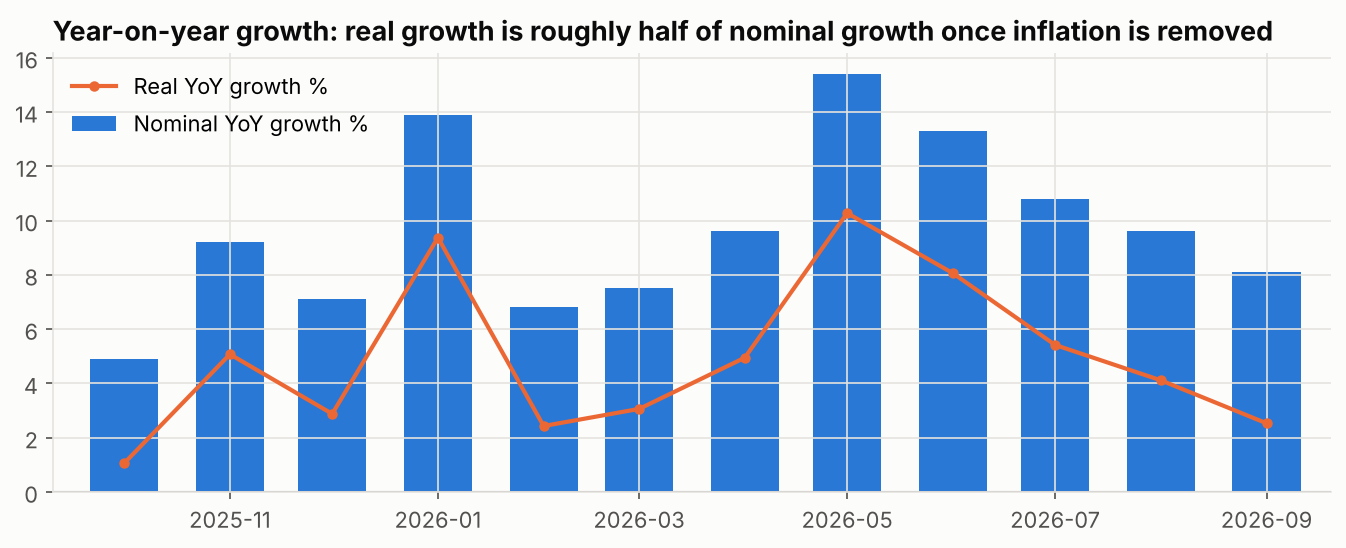

In [5]:
fig, ax = plt.subplots(figsize=(11, 3.8))
x = pd.to_datetime(trend.month_start)
ax.bar(x, trend.yoy_growth_pct, width=20, color=[PALETTE[0]] * len(x), label="Nominal YoY growth %")
real_yoy = 100 * (trend.real_revenue_oct24_kes / trend.real_revenue_oct24_kes.shift(12) - 1)
ax.plot(x, real_yoy, color=PALETTE[1], marker="o", ms=4, label="Real YoY growth %")
ax.axhline(0, color="#999", lw=1)
ax.set_title("Year-on-year growth: real growth is roughly half of nominal growth once inflation is removed")
ax.legend(loc="upper left")
ax.set_xlim(pd.Timestamp("2025-09-10"), pd.Timestamp("2026-09-20"))
fig.savefig(FIGURES / "10_yoy_growth.png")

## Q3 - Top products per category

In [6]:
run("q03_top_products_per_category", show=27)

,category,product_name,revenue,units,rank_in_category,pct_of_category
0,Staples,Vegetable Cooking Oil 3L,8467314,8204,1,37.8
1,Staples,White Sugar 2kg,7245445,19771,2,32.4
2,Staples,Vegetable Cooking Oil 1L,6664294,18275,3,29.8
3,Fresh Produce,Beef Steak per kg,3873505,4783,1,34.9
4,Fresh Produce,Eggs Tray 30,3857365,7931,2,34.8
5,Fresh Produce,Whole Chicken 1.2kg,3363795,4777,3,30.3
6,Household,Toilet Paper 10 Pack,4091400,9385,1,39.0
7,Household,Gas Refill 6kg,3317115,2363,2,31.6
8,Household,Washing Powder 1kg,3082181,9250,3,29.4
9,Baby & Kids,Baby Diapers 40s,4413980,3390,1,51.7


## Q4 - Category mix by county (first two counties shown)

In [7]:
mix = run("q04_category_mix_by_county", show=None)
mix.pivot(index="category", columns="county", values="pct_of_county").round(1)

county,Kajiado,Kakamega,Kiambu,Kilifi,Kisumu,Machakos,Mombasa,Nairobi,Nakuru,Nyeri,Uasin Gishu
category,,,,,,,,,,,
Baby & Kids,6.6,6.7,6.7,6.7,6.4,6.1,6.7,6.7,6.3,6.3,6.1
Beverages,11.9,11.5,12.0,11.7,12.3,11.8,11.9,11.9,11.8,11.8,12.0
Dairy,5.9,5.8,5.6,6.1,5.6,5.7,5.6,5.8,5.6,5.3,5.7
Electronics & Phone,3.9,3.8,3.5,3.5,3.4,3.5,3.6,3.5,3.6,3.5,3.6
Fresh Produce,15.0,15.9,15.3,15.6,15.3,15.8,15.6,15.4,15.8,15.4,15.4
Household,12.5,12.6,13.1,11.6,12.6,12.3,12.7,12.9,12.9,12.4,12.6
Personal Care,6.9,7.1,7.0,7.6,7.1,6.7,6.8,7.0,7.0,7.4,6.8
Staples,33.3,32.8,33.3,33.1,33.2,34.3,33.4,33.1,33.2,33.7,33.9
Stationery & School,4.1,3.8,3.5,4.1,4.0,3.9,3.8,3.7,4.0,4.2,3.9


Category mix is remarkably stable across counties (staples ~33% everywhere), so a single national range with local
tweaks is reasonable.

## Q5 - Payment mix (conditional aggregation)

In [8]:
run("q05_payment_mix")

,quarter,receipts,mpesa_pct,cash_pct,card_pct,airtel_pct,mpesa_avg_basket,cash_avg_basket,card_avg_basket
0,2024-10-01,45730,55.2,27.7,13.4,2.8,863,850,1052
1,2025-01-01,35314,55.4,27.4,13.6,2.9,843,826,1026
2,2025-04-01,39442,56.4,26.9,13.1,2.7,846,835,1032
3,2025-07-01,40729,56.2,26.6,13.6,2.8,864,845,1053
4,2025-10-01,46667,57.6,25.3,13.4,2.8,906,900,1089
5,2026-01-01,36903,58.2,24.6,13.5,2.9,879,870,1076
6,2026-04-01,41545,58.9,23.5,13.7,3.0,900,907,1105
7,2026-07-01,41914,59.2,23.1,13.9,3.0,915,902,1123


## Q6 - Cohort retention

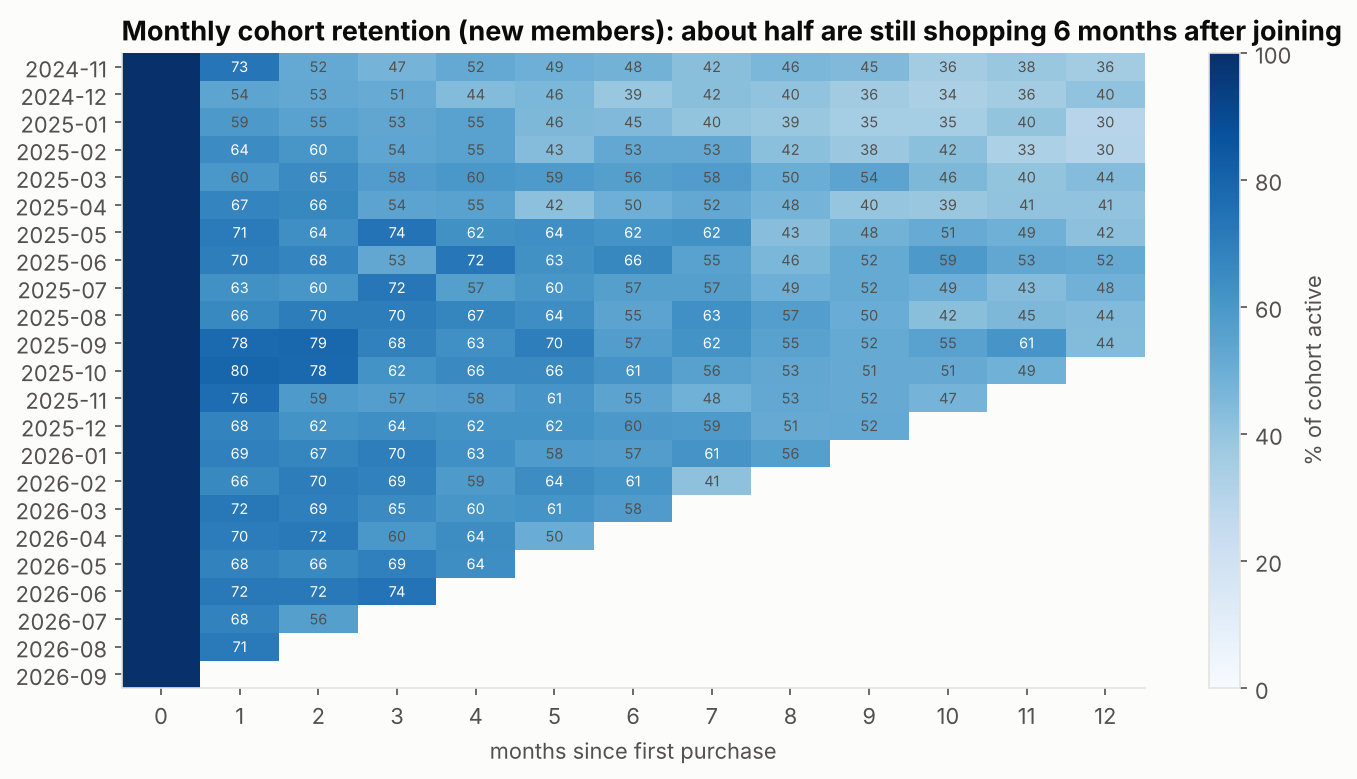

In [9]:
coh = run("q06_cohort_retention", show=None)
grid = coh.pivot(index="cohort_month", columns="months_since", values="retention_pct")
grid = grid[grid.index >= "2024-11-01"]       # the Oct-24 'cohort' mixes years of existing members
fig, ax = plt.subplots(figsize=(11, 5.5))
im = ax.imshow(grid, aspect="auto", cmap="Blues", vmin=0, vmax=100)
ax.set_yticks(range(len(grid)), [d[:7] for d in grid.index])
ax.set_xticks(range(grid.shape[1]), grid.columns)
ax.set_xlabel("months since first purchase"); ax.grid(False)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.iat[i, j]
        if pd.notna(v) and j > 0:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                    color="white" if v > 60 else TEXT_2)
fig.colorbar(im, ax=ax, label="% of cohort active")
ax.set_title("Monthly cohort retention (new members): about half are still shopping 6 months after joining")
fig.savefig(FIGURES / "11_cohort_retention.png")

In [10]:
avg_curve = grid.mean().round(1)
print("Average retention curve (% active by month since first purchase):")
print(avg_curve.to_string())

Average retention curve (% active by month since first purchase):
months_since
0     100.0
1      68.4
2      64.9
3      62.2
4      59.9
5      57.1
6      55.2
7      53.3
8      48.5
9      46.9
10     45.1
11     44.0
12     40.9


## Q7-Q8 - RFM segmentation

In [11]:
rfm = run("q07_rfm_segments", show=None)
rfm.head()

,customer_id,recency_days,frequency_12m,monetary_12m,r_score,f_score,m_score,rfm_code,rfm_segment
0,C00334,0,166,168669,5,5,5,555,Champions
1,C01838,0,108,166432,5,5,5,555,Champions
2,C05445,2,138,166427,5,5,5,555,Champions
3,C01899,4,104,165188,5,5,5,555,Champions
4,C04025,1,133,154625,5,5,5,555,Champions


In [12]:
seg = run("q08_rfm_segment_summary", show=None)
seg

,rfm_segment,customers,pct_customers,revenue_12m,pct_revenue,avg_recency_days,avg_frequency
0,Champions,1688,30.5,65975044,78.8,9,37.4
1,Loyal,1358,24.5,15042295,18.0,84,11.6
2,At Risk,1107,20.0,2193724,2.6,364,2.0
3,Needs Attention,174,3.1,276974,0.3,123,1.8
4,New / Promising,101,1.8,184649,0.2,17,1.8
5,Lost / Hibernating,1108,20.0,0,0.0,619,0.0


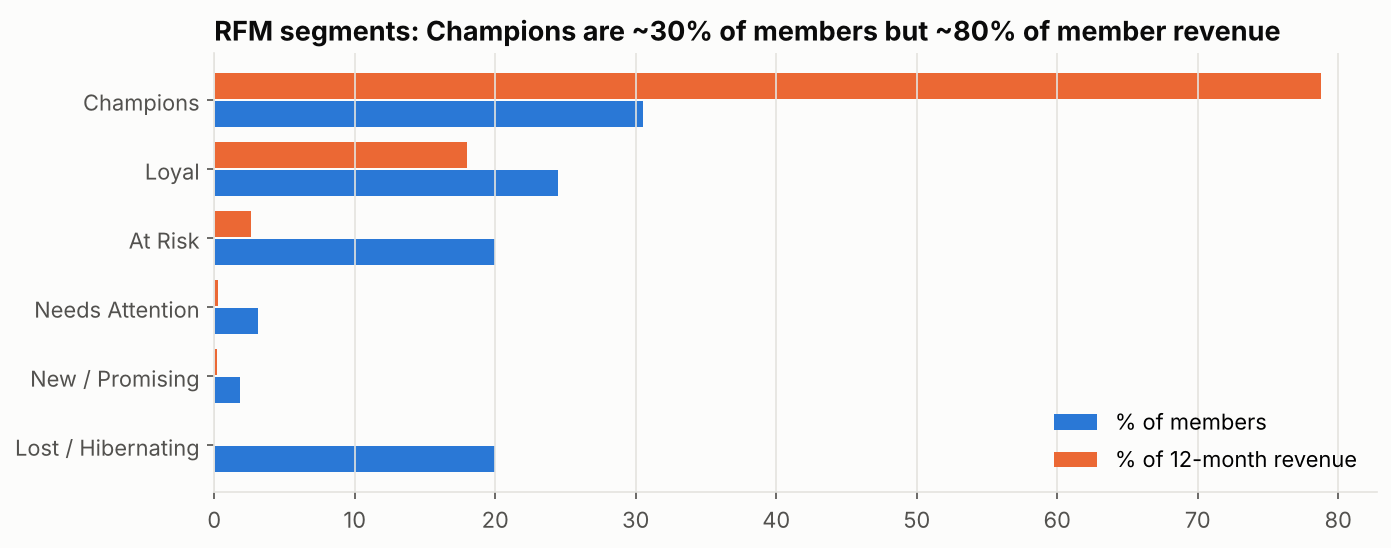

In [13]:
fig, ax = plt.subplots(figsize=(10, 3.8))
s = seg.set_index("rfm_segment")
y = range(len(s))
ax.barh([i + 0.2 for i in y], s.pct_customers, height=0.38, color=PALETTE[0], label="% of members")
ax.barh([i - 0.2 for i in y], s.pct_revenue, height=0.38, color=PALETTE[1], label="% of 12-month revenue")
ax.set_yticks(list(y), s.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_title("RFM segments: Champions are ~30% of members but ~80% of member revenue")
ax.legend(loc="lower right")
fig.savefig(FIGURES / "12_rfm_segments.png")

**So what?** Protect Champions (service, availability, recognition); push Loyal members up with personalised offers;
run a cheap win-back for *At Risk*; don't spend on *Lost*.

## Q9 - Did the cooking-oil promotion work? (difference-in-differences)

In [14]:
print(Q["q09_promo_cooking_oil_did"])
run("q09_promo_cooking_oil_did")

-- Q9. Did the March 2026 cooking-oil promotion work? Average daily cooking-oil units per
-- store, before (4 weeks) vs during (3 weeks), in test vs control stores -> difference-in-differences.
WITH promo AS (
    SELECT start_date, end_date, string_to_array(store_ids, '|') AS stores
    FROM   retail.dim_promotion WHERE promo_id = 'PR008'
),
daily AS (
    SELECT  t.store_id, t.date_key, SUM(l.quantity) AS units
    FROM    retail.fact_sales_line l
    JOIN    retail.fact_transaction t USING (transaction_id)
    JOIN    retail.dim_product p USING (product_id)
    WHERE   p.subcategory = 'Cooking Oil'
      AND   t.date_key BETWEEN DATE '2026-02-02' AND DATE '2026-03-22'
    GROUP BY t.store_id, t.date_key
),
labelled AS (
    SELECT  d.*,
            CASE WHEN d.store_id = ANY (pr.stores) THEN 'Test' ELSE 'Control' END            AS grp,
            CASE WHEN d.date_key >= pr.start_date THEN 'During' ELSE 'Before' END              AS period
    FROM    daily d CROSS JOIN promo pr
    

,grp,period,avg_daily_units_per_store,stores,change_vs_before_pct
0,Test,Before,5.19,10,0.0
1,Test,During,7.10,10,36.8
2,Control,Before,4.85,9,0.0
3,Control,During,4.40,9,-9.3


Test stores' cooking-oil sales rose ~37% during the promotion while control stores fell slightly - a difference-in-differences
of roughly +45 percentage points. Milestone 5 tests whether this is statistically significant.

## Q10 - Market penetration (census join)

In [15]:
run("q10_county_penetration", show=12)

,county,population_2019,stores,revenue_12m,revenue_per_1000_residents,residents_per_store
0,Mombasa,1208333,2,23113052,19128,604167.0
1,Kisumu,1155574,2,18044215,15615,577787.0
2,Nairobi,4397073,6,48403051,11008,732846.0
3,Nyeri,759164,1,6928365,9126,759164.0
4,Nakuru,2162202,2,18526985,8569,1081101.0
5,Uasin Gishu,1163186,1,8301721,7137,1163186.0
6,Kiambu,2417735,2,11246512,4652,1208868.0
7,Machakos,1421932,1,6243791,4391,1421932.0
8,Kajiado,1117840,1,4317926,3863,1117840.0
9,Kakamega,1867579,1,6409045,3432,1867579.0


Meru (1.55M residents, no store) and Kakamega/Kilifi (over 1.4M residents per store) are the clearest white-space.

## Q11-Q12 - Drifting regulars

In [16]:
drift = run("q11_drifting_customers", show=None)
print(f"{len(drift)} regular customers have drifted; they spent KES {drift.spend_h1.sum():,.0f} in H1 2026")
drift.head(10)

274 regular customers have drifted; they spent KES 3,641,300 in H1 2026


,customer_id,home_store_id,county,visits_h1,visits_q3,spend_h1,last_visit,days_since_last_visit
0,C00943,S015,Uasin Gishu,46,3,51241,2026-07-17,75
1,C02478,S013,Kisumu,43,2,40949,2026-07-17,75
2,C05183,S004,Nairobi,37,3,40062,2026-08-13,48
3,C01228,S007,Mombasa,38,4,39739,2026-07-16,76
4,C05513,S011,Nakuru,28,8,39690,2026-07-31,61
5,C01575,S004,Nairobi,38,1,39067,2026-07-18,74
6,C01913,S006,Nairobi,47,2,38117,2026-07-31,61
7,C01841,S009,Kiambu,36,2,37755,2026-07-13,79
8,C04799,S001,Nairobi,31,8,37367,2026-08-14,47
9,C01057,S003,Nairobi,32,5,36833,2026-07-29,63


In [17]:
run("q12_drifting_by_county")

,county,regulars_h1,drifting,drifting_pct
0,Nakuru,191,52,27.2
1,Kilifi,40,8,20.0
2,Kiambu,126,21,16.7
3,Mombasa,267,44,16.5
4,Uasin Gishu,121,20,16.5
5,Machakos,65,10,15.4
6,Nairobi,558,76,13.6
7,Kajiado,23,3,13.0
8,Kisumu,186,23,12.4
9,Nyeri,77,9,11.7


Nakuru has by far the highest share of drifting regulars - matching the traffic drop seen in the EDA.

## Q13 - What is bought together?

In [18]:
run("q13_basket_affinity", show=10)

,product_a,product_b,baskets_together,support_pct,confidence_a_to_b_pct,lift
0,Exercise Books A5 10 Pack,Ball Pens 10 Pack,587,0.70,46.3,22.93
1,Baby Diapers 40s,Baby Wipes 80s,584,0.70,40.4,16.49
2,White Sugar 1kg,Kenya Tea Leaves 500g,1487,1.78,21.9,4.25
3,Spaghetti 400g,Tomatoes per kg,634,0.76,28.8,4.00
4,Maize Flour 2kg,Sukuma Wiki Bunch,2818,3.38,29.4,3.62
5,Vegetable Cooking Oil 1L,Onions per kg,1166,1.40,19.6,2.82
6,White Bread 400g,Fresh Milk 500ml,3168,3.80,37.0,2.57
7,Vegetable Cooking Oil 1L,Cooking Fat 500g,247,0.30,4.2,1.06
8,White Bread 400g,Toothpaste 140g,327,0.39,3.8,1.05
9,Long Grain Rice 1kg,White Sugar 1kg,294,0.35,8.5,1.05


Strong, actionable pairs: exercise books and pens (lift ~23), diapers and wipes, tea and sugar, unga and sukuma wiki,
bread and milk. Use them for shelf adjacency and bundle offers (e.g. "Tea + Sugar" combo).

## Q14-Q15 - Calendar effects and like-for-like growth

In [19]:
run("q14_calendar_effects")

,condition,avg_daily_revenue,days
0,Public holiday,336061,25
1,Non-holiday,408172,705
2,Weekend,509659,208
3,Weekday,364279,522
4,Payday window (25th-3rd),483581,226
5,Rest of month,370781,504


In [20]:
run("q15_store_yoy_growth", show=19)

,store_name,county,revenue_y1,revenue_y2,nominal_growth_pct,real_growth_pct,growth_rank
0,Mavuno Mart Kondele,Kisumu,2865447,3440289,20.1,14.8,1
1,Mavuno Mart Rongai,Nairobi,3456984,3995713,15.6,10.6,2
2,Mavuno Mart CBD Moi Avenue,Nairobi,8241127,9187761,11.5,6.6,3
3,Mavuno Mart Kasarani,Nairobi,7232432,8057863,11.4,6.6,4
4,Mavuno Mart Malindi,Kilifi,2964692,3296843,11.2,6.3,5
5,Mavuno Mart Kisumu Mega,Kisumu,13235177,14603926,10.3,5.6,6
6,Mavuno Mart Nyali,Mombasa,13703574,15101007,10.2,5.4,7
7,Mavuno Mart Karen,Nairobi,3231065,3515972,8.8,4.1,8
8,Mavuno Mart Mombasa Town,Mombasa,7387508,8012045,8.5,3.8,9
9,Mavuno Mart Kakamega,Kakamega,5919409,6409045,8.3,3.5,10
